# Día 2 — Evaluación y árboles de regresión

**Módulo 3: Machine Learning Aplicado — CEC EPN / Banco Central del Ecuador**  
**Fecha:** 14-10-2026

Este notebook continúa desde el Día 1. Primero retomamos regresión lineal y comparamos Holdout con K-Fold sobre los mismos indicadores; luego estudiamos árboles y Random Forest en regresión con un segundo dataset, más grande, de clientes de tarjeta de crédito. La clasificación empieza desde cero en el Día 3.

## Datos que utilizaremos

1. **`datos/world_bank_latam_ml.csv`**: panel país-año de indicadores macroeconómicos descargado previamente desde World Development Indicators. Se carga desde disco; durante la clase no se realizan peticiones al Banco Mundial.
2. **`datos/BankChurners.csv`**: 10 127 clientes de tarjeta de crédito con su actividad transaccional, límite de crédito y relación con el banco. Lo usamos desde la sección 7 para árboles y Random Forest; su descripción completa está en la sección 7.1.

## Objetivos

- revisar y limpiar un dataset antes de modelar;
- comparar Holdout y K-Fold con MAE, MSE, RMSE, R² y Bias;
- reconocer underfitting y overfitting al cambiar la complejidad;
- producir predicciones usando un Holdout y un modelo reajustado después de K-Fold;
- entender árboles y Random Forest para regresión y comparar sus errores fuera de Train;
- ver gráficamente cómo un árbol divide los datos y cómo cambia al mover `max_depth`, `min_samples_split` y `min_samples_leaf`.



# 0. Librerías

Las librerías utilizadas forman parte de una instalación habitual de Anaconda / scikit-learn.

In [1]:
# Importamos herramientas numéricas, de datos, visualización y modelos; estos imports no entrenan nada.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_validate
)

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.dummy import DummyRegressor
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression

from sklearn.tree import (
    DecisionTreeRegressor,
    DecisionTreeClassifier,
    plot_tree
)

from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay
)

# 1. Ruta de la jornada: medir antes de complicar el modelo

Primero revisaremos el panel macroeconómico y definiremos una regresión de referencia. Después evaluaremos el mismo problema con una partición Holdout y con K-Fold, usando las cinco métricas del Día 1. A partir de Train y Validation reconoceremos underfitting/overfitting; al comenzar los árboles introduciremos sus configuraciones de complejidad. Para los árboles cambiaremos de datos: el panel tiene 127 filas completas y un árbol necesita muchas más observaciones para encontrar reglas estables. Usaremos 10 127 clientes de tarjeta de crédito (BankChurners), veremos cómo divide el árbol, jugaremos con sus tres hiperparámetros y cerraremos con Random Forest. La clasificación comienza en el Día 3.

# 2. Indicadores macroeconómicos del Banco Mundial

El archivo `datos/world_bank_latam_ml.csv` contiene una copia descargada previamente de indicadores públicos del Banco Mundial.

La tabla fue armada con seis indicadores anuales para siete países latinoamericanos entre 2005 y 2024. La unidad de observación es `país-año`; no es una serie exclusiva de Ecuador. Conservamos los mismos predictores y el mismo target que el ejercicio anterior para centrarnos en evaluación, overfitting y generalización.

| Columna | Significado | Papel en esta práctica |
|---|---|---|
| `iso3`, `pais` | Identificador de país | Describir y rastrear filas; no entran al modelo lineal |
| `anio` | Año de observación | Identificar periodo; no entra al modelo |
| `crecimiento_pib_pct` | Variación anual del PIB (%) | Target `y` |
| `inflacion_pct` | Inflación anual (%) | Predictor `X` |
| `desempleo_pct` | Desempleo (%) | Predictor `X` |
| `exportaciones_pct_pib` | Exportaciones como porcentaje del PIB | Predictor `X` |
| `inversion_pct_pib` | Formación bruta de capital como porcentaje del PIB | Predictor `X` |
| `crecimiento_poblacion_pct` | Crecimiento poblacional anual (%) | Predictor `X` |

**Fuente:** World Development Indicators, Banco Mundial.

In [2]:
# Igual que el Día 1: buscar datos desde notebooks/ y luego desde la raíz.
DATA_DIR = Path('../datos')
if not DATA_DIR.exists():
    DATA_DIR = Path('datos')

ARCHIVO_WB = DATA_DIR / 'world_bank_latam_ml.csv'
if not ARCHIVO_WB.exists():
    raise FileNotFoundError(f'Falta {ARCHIVO_WB.resolve()}; conserva datos/ junto con notebooks/.')

# Leer una copia fija: no hay petición web ni descarga durante la clase.
df_wb = pd.read_csv(ARCHIVO_WB)
print('Usando datos desde:', DATA_DIR.resolve())
print('Dimensiones:', df_wb.shape)
df_wb.head()


Usando datos desde: C:\Users\Usuario iTC\Desktop\modulo3_ml\datos
Dimensiones: (140, 9)


,iso3,pais,anio,crecimiento_pib_pct,inflacion_pct,desempleo_pct,exportaciones_pct_pib,inversion_pct_pib,crecimiento_poblacion_pct
0,ARG,Argentina,2005,8.851660,NaN,11.506,23.245877,18.888264,1.027458
1,ARG,Argentina,2006,8.047152,NaN,10.078,23.026695,18.680487,1.028248
2,ARG,Argentina,2007,9.007651,NaN,8.470,22.662750,20.099113,0.991102
3,ARG,Argentina,2008,4.057233,NaN,7.837,22.060900,19.572776,1.012889
4,ARG,Argentina,2009,-5.918525,NaN,8.645,19.560985,16.053112,1.059775


# 3. Conocer, revisar y limpiar el dataset antes de modelar

Antes de entrenar, averiguamos qué contiene el archivo y qué representa cada fila. `shape` da filas y columnas; `dtypes` muestra los tipos que interpretó Pandas; `describe()` resume las distribuciones numéricas. Revisamos además que cada par `iso3-anio` identifique una sola observación.

La variable que intentaremos estimar es `crecimiento_pib_pct`. Usaremos cinco indicadores como predictores y conservaremos `pais`, `iso3` y `anio` para interpretar y rastrear las observaciones, no como entradas de la regresión. Esta es una práctica predictiva transversal sobre un panel; no es todavía un pronóstico temporal ni una afirmación causal.

In [3]:
# Revisamos dimensiones, tipos, clave país-año y cobertura temporal antes de definir el modelo.
print('Dimensiones:')
print(df_wb.shape)
print('Duplicados país-año:', df_wb.duplicated(['iso3', 'anio']).sum())

print('\nTipos:')
print(df_wb.dtypes)

print('\nPaíses:')
print(
    sorted(
        df_wb['pais']
        .dropna()
        .unique()
    )
)

print(
    '\nRango temporal:',
    df_wb['anio'].min(),
    '-',
    df_wb['anio'].max()
)

Dimensiones:
(140, 9)
Duplicados país-año: 0

Tipos:
iso3                          object
pais                          object
anio                           int64
crecimiento_pib_pct          float64
inflacion_pct                float64
desempleo_pct                float64
exportaciones_pct_pib        float64
inversion_pct_pib            float64
crecimiento_poblacion_pct    float64
dtype: object

Países:
['Argentina', 'Brazil', 'Chile', 'Colombia', 'Ecuador', 'Mexico', 'Peru']

Rango temporal: 2005 - 2024


In [4]:
# Contamos valores ausentes por columna; un dato faltante no equivale a cero.
nulos_wb = (
    df_wb
    .isna()
    .sum()
    .sort_values(ascending=False)
)

nulos_wb[nulos_wb > 0]

inflacion_pct    13
dtype: int64

## Datos faltantes y regla de limpieza

Una ausencia puede significar que el país no reportó ese indicador en ese año; no equivale a cero. Contamos faltantes por columna y no imputamos automáticamente: rellenar inflación con cero inventaría información. Para este ejercicio se retendrán observaciones completas en el target y los cinco predictores, y anotaremos cuántas quedan.

La fuente contiene 140 país-año y 13 valores faltantes en inflación; el filtro deja 127 observaciones completas. Como faltan sobre todo años de Argentina, la muestra final puede representar de manera distinta países y periodos. En una aplicación se investigaría el patrón de ausencia y se evaluaría su impacto antes de elegir entre eliminar e imputar.

> **Nota para quien viene de estadística:** en la celda siguiente, `*FEATURES_WB` dentro de la lista significa "inserta aquí, una por una, todas las columnas de la lista `FEATURES_WB`" — el mismo desempaquetado con `*` que se explica en el notebook complementario [Día 0.1, Sección 3](00_1_Dia0_Puente_a_Scikit_Learn.ipynb), aplicado esta vez dentro de una lista en vez de en una llamada a función. El resultado es una lista más larga, sin tener que escribir cada nombre dos veces.

In [5]:
# Elegimos predictores/target y contamos cuántas filas completas quedan después de la limpieza.
FEATURES_WB = [
    'inflacion_pct',
    'desempleo_pct',
    'exportaciones_pct_pib',
    'inversion_pct_pib',
    'crecimiento_poblacion_pct'
]

TARGET_WB = 'crecimiento_pib_pct'

df_wb_modelo = (
    df_wb[
        [
            'iso3',
            'pais',
            'anio',
            *FEATURES_WB,
            TARGET_WB
        ]
    ]
    .dropna()
    .reset_index(drop=True)
)

print(
    'Observaciones utilizables:',
    len(df_wb_modelo)
)

df_wb_modelo.head()

Observaciones utilizables: 127


,iso3,pais,anio,inflacion_pct,desempleo_pct,exportaciones_pct_pib,inversion_pct_pib,crecimiento_poblacion_pct,crecimiento_pib_pct
0,ARG,Argentina,2018,34.277224,9.220,14.436686,16.613885,0.822969,-2.617396
1,ARG,Argentina,2019,53.548304,9.843,17.924878,14.210030,0.710901,-2.000861
2,ARG,Argentina,2020,42.015095,11.461,16.605414,14.415156,0.484666,-9.900485
3,ARG,Argentina,2021,48.409379,8.736,18.066709,18.076289,0.265879,10.441812
4,ARG,Argentina,2022,72.430758,6.805,16.281668,17.385586,0.210809,6.020745


## 3.1 Formular el problema supervisado

Para cada fila país-año tomamos como `X` los indicadores de inflación, desempleo, exportaciones, inversión y crecimiento de la población. `y` es el crecimiento anual del PIB, medido en porcentaje.

El algoritmo aprende asociaciones de la muestra histórica para estimar `y` en una fila nueva. No afirmamos que mover inflación o inversión cause el cambio predicho. Además, como varios años pertenecen a cada país, filas cercanas pueden parecerse; una partición aleatoria enseña el método, pero no mide por sí sola el desempeño en un país nuevo o en un año futuro.

In [6]:
# Separamos X (cinco indicadores) e y (crecimiento del PIB) y miramos rangos de entrada.
X_wb = df_wb_modelo[FEATURES_WB]
y_wb = df_wb_modelo[TARGET_WB]

X_wb.describe().round(2)

,inflacion_pct,desempleo_pct,exportaciones_pct_pib,inversion_pct_pib,crecimiento_poblacion_pct
count,127.00,127.00,127.00,127.00,127.00
mean,8.69,6.84,25.30,21.49,1.06
std,24.02,3.13,8.94,3.06,0.39
min,-0.34,2.68,10.85,14.21,0.21
25%,2.92,3.82,16.62,19.61,0.81
50%,3.81,6.76,26.51,22.03,0.99
75%,5.54,9.26,31.53,23.51,1.36
max,219.88,15.98,45.13,28.90,1.84


## Métricas comunes para que la comparación sea justa

Las métricas responden preguntas distintas y deben calcularse sobre las mismas filas:

- **MAE:** tamaño absoluto medio del error, en puntos porcentuales; menor es mejor.
- **MSE:** media del error al cuadrado; mantiene unidades cuadradas y castiga con fuerza errores grandes.
- **RMSE:** raíz de MSE; vuelve a puntos porcentuales, pero conserva mayor sensibilidad a errores extremos.
- **R²:** mejora relativa frente a predecir la media; puede ser negativo si el modelo generaliza mal.
- **Bias:** media de `predicción − valor real`; positivo indica sobrepredicción sistemática, negativo subpredicción.

Usaremos una sola función —la misma lógica del Día 1— para no comparar tablas calculadas con definiciones diferentes.

In [7]:
# Definimos una única función: MAE, MSE, RMSE, R² y Bias con Bias = predicción − valor real.
def metricas_regresion(y_real, y_pred):
    y_real = np.asarray(y_real)
    y_pred = np.asarray(y_pred)
    mse = mean_squared_error(y_real, y_pred)
    return {
        "MAE": mean_absolute_error(y_real, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_real, y_pred),
        # Mismo signo que el Día 1: positivo = sobreestimación media.
        "Bias": np.mean(y_pred - y_real),
    }


# 4. Underfitting y overfitting: primero en una regresión lineal

El Día 1 mostró que una regresión puede entrenarse bien y aun así fallar en Validation. **Underfitting** significa que incluso Train tiene mucho error: la representación es demasiado limitada o falta información. **Overfitting** significa que Train mejora extraordinariamente, pero Validation se deteriora: el modelo aprendió peculiaridades de esas filas. Un buen ajuste combina un error útil en Validation con una brecha Train–Validation razonable.

Para ver los tres patrones en el mismo dataset compararemos: una constante (subajuste deliberado), la regresión lineal múltiple y una regresión lineal sobre términos polinómicos más flexibles. El último *sigue siendo* regresión lineal respecto a sus coeficientes, aunque recibe columnas transformadas. Ningún ejemplo garantiza por decreto un diagnóstico; miraremos sus métricas y los errores del baseline antes de etiquetarlo.


# 5. La división del Día 1: 70 % Train, 15 % Validation, 15 % Test

Reservamos primero un **30 %** en `X_temp_wb`; lo dividimos por la mitad: 15 % Validation y 15 % Test. Train queda con el 70 % original. Las cantidades son aproximadas porque 127 filas no se dividen exactamente en esos porcentajes.

Train ajusta coeficientes y transformaciones; Validation compara modelos y diagnostica sub/sobreajuste; Test se reserva hasta cerrar una decisión. K-Fold posterior utiliza únicamente el conjunto de **desarrollo** (Train + Validation) y tampoco ve Test. El mismo panel contiene distintos años de cada país, así que esto enseña evaluación aleatoria, no forecasting temporal ni generalización a países no vistos.


In [8]:
# Misma secuencia que el Día 1: 70 % entrenamiento y 30 % temporal.
X_train_wb, X_temp_wb, y_train_wb, y_temp_wb = train_test_split(
    X_wb, y_wb, test_size=0.30, random_state=42
)
# Dividir ese temporal por la mitad produce 15 % Validation y 15 % Test.
X_val_wb, X_test_wb, y_val_wb, y_test_wb = train_test_split(
    X_temp_wb, y_temp_wb, test_size=0.50, random_state=42
)
# Solo Train + Validation son datos de desarrollo para las cinco vueltas de CV.
X_dev_wb = X_wb.loc[X_train_wb.index.union(X_val_wb.index)]
y_dev_wb = y_wb.loc[X_dev_wb.index]
assert set(X_dev_wb.index).isdisjoint(set(X_test_wb.index))
print('Train:', X_train_wb.shape, 'Validation:', X_val_wb.shape,
      'Test:', X_test_wb.shape)


Train: (88, 5) Validation: (19, 5) Test: (20, 5)


## 5.1 Regresión lineal: medir Train y Validation

El ajuste ordinario del Día 1 se repite con cinco predictores económicos. Calcularemos MAE, MSE, RMSE, R² y Bias tanto en filas vistas como en filas apartadas. En la misma Validation, un `DummyRegressor` que siempre predice la media de Train muestra qué logra una estrategia sin aprender relaciones. No juzgues el error de un modelo sin una referencia.


> **Nota para quien viene de estadística:** de aquí en adelante vas a ver muchas veces el patrón `{'modelo': nombre, **metricas_regresion(...)}`. El doble asterisco `**` "desempaqueta" el diccionario que devuelve `metricas_regresion` (con MAE, MSE, RMSE, Bias y R²) directamente dentro de otro diccionario más grande. Si esta sintaxis no te resulta familiar, el notebook complementario [Día 0.1, Sección 3.3](00_1_Dia0_Puente_a_Scikit_Learn.ipynb) la explica paso a paso con un ejemplo pequeño.

In [10]:
# Holdout lineal: ajustamos solo con el 70 % Train.
modelo_lineal_holdout = LinearRegression().fit(X_train_wb, y_train_wb)
pred_train_holdout = modelo_lineal_holdout.predict(X_train_wb)
pred_val_holdout = modelo_lineal_holdout.predict(X_val_wb)

# La constante aprende únicamente la media de Train.
baseline_wb = DummyRegressor(strategy='mean').fit(X_train_wb, y_train_wb)
pred_base_train = baseline_wb.predict(X_train_wb)
pred_base_val = baseline_wb.predict(X_val_wb)

tabla_holdout = pd.DataFrame([
    {'modelo': 'Baseline media', 'conjunto': 'Train',
     **metricas_regresion(y_train_wb, pred_base_train)},
    {'modelo': 'Baseline media', 'conjunto': 'Validation',
     **metricas_regresion(y_val_wb, pred_base_val)},
    {'modelo': 'Regresión lineal múltiple', 'conjunto': 'Train',
     **metricas_regresion(y_train_wb, pred_train_holdout)},
    {'modelo': 'Regresión lineal múltiple', 'conjunto': 'Validation',
     **metricas_regresion(y_val_wb, pred_val_holdout)},
])
tabla_holdout.set_index(['modelo', 'conjunto']).round(3)


MAE     MSE   RMSE     R2   Bias
modelo                    conjunto                                      
Baseline media            Train       2.911  17.190  4.146  0.000 -0.000
                          Validation  3.540  19.010  4.360 -0.122  1.439
Regresión lineal múltiple Train       2.739  14.533  3.812  0.155  0.000
                          Validation  3.394  18.989  4.358 -0.121  1.697

### Lee la tabla antes de concluir

MAE de 2,5 significa un error absoluto promedio de **2,5 puntos porcentuales** de crecimiento anual; MSE está en puntos porcentuales al cuadrado. Si la regresión mejora el MAE/RMSE del baseline en Validation, hay señal predictiva en esta partición. R² próximo a cero o negativo en Validation obliga a moderar conclusiones, aunque Train parezca bueno. Bias positivo es tendencia media a sobreestimar y negativo a subestimar; Bias cercano a cero no implica errores individuales pequeños.

La brecha Train–Validation es necesaria para diagnosticar ajuste, pero también debes comparar el rendimiento absoluto con un baseline. Una regresión con Train y Validation igualmente malos puede sufrir subajuste, no necesariamente generalizar bien.


## 5.2 Demostración controlada: capacidad insuficiente frente a flexibilidad excesiva

**Paso A:** `DummyRegressor` siempre usa la media, incapaz de representar efectos de inflación, inversión o exportaciones; sirve como caso de capacidad mínima. **Paso B:** la regresión lineal múltiple modela una combinación de las cinco variables. **Paso C:** `PolynomialFeatures(degree=3)` crea cuadrados, cubos e interacciones; una regresión lineal sobre esas columnas puede ajustarse mucho más a Train y, con esta muestra pequeña, sobreajustar Validation.

Comparamos sobre **las mismas filas** y no usamos Test. La palabra «underfitting» describe resultados observados, no un nombre intrínseco del algoritmo: si el baseline ya fuera bueno, habría que reconocerlo.


In [11]:
# Expandimos las cinco features SOLO dentro de Train con un Pipeline.
# La regresión sigue siendo lineal en sus coeficientes, no en las features originales.
polinomica = make_pipeline(
    PolynomialFeatures(degree=3, include_bias=False),
    LinearRegression()
).fit(X_train_wb, y_train_wb)

modelos_lineales = {
    'Constante (muy simple)': baseline_wb,
    'Regresión lineal múltiple': modelo_lineal_holdout,
    'Regresión con términos de grado 3': polinomica,
}
filas_ajuste_lineal = []
for nombre, modelo in modelos_lineales.items():
    # Cada modelo ve Train y se examina en las mismas filas Validation.
    for conjunto, X_parte, y_parte in [
        ('Train', X_train_wb, y_train_wb),
        ('Validation', X_val_wb, y_val_wb),
    ]:
        pred = modelo.predict(X_parte)
        filas_ajuste_lineal.append({
            'modelo': nombre, 'conjunto': conjunto,
            **metricas_regresion(y_parte, pred),
        })
tabla_ajuste_lineal = pd.DataFrame(filas_ajuste_lineal)
tabla_ajuste_lineal.set_index(['modelo', 'conjunto']).round(3)


MAE       MSE    RMSE  \
modelo                            conjunto                               
Constante (muy simple)            Train        2.911    17.190   4.146   
                                  Validation   3.540    19.010   4.360   
Regresión lineal múltiple         Train        2.739    14.533   3.812   
                                  Validation   3.394    18.989   4.358   
Regresión con términos de grado 3 Train        1.374     3.617   1.902   
                                  Validation  14.743  1389.921  37.282   

                                                  R2    Bias  
modelo                            conjunto                    
Constante (muy simple)            Train        0.000  -0.000  
                                  Validation  -0.122   1.439  
Regresión lineal múltiple         Train        0.155   0.000  
                                  Validation  -0.121   1.697  
Regresión con términos de grado 3 Train        0.790  -0.000  
                                  Validation -81.054  12.440

### Diagnostica con números, no con el nombre del estimador

Mira primero si la constante falla en Train y Validation; eso revela que una predicción única no capta variación. La regresión múltiple puede mejorar ambos errores sin gran brecha. El modelo polinómico puede alcanzar error Train muy pequeño y un Validation peor: esa divergencia, no la mera existencia de términos cúbicos, es la evidencia de overfitting. Si sucede algo distinto con otra versión de datos, interpreta *esa* salida.

Un modelo con Train y Validation parecidos pero ambos peores que el baseline también carece de utilidad. Un Bias pequeño puede ocultar grandes errores positivos y negativos que se cancelan: léelo junto con MAE y RMSE. ¿Qué modelo llevarías al Test si priorizas reducir error absoluto, y por qué?


# 6. K-Fold: repetir la validación sin tocar Test

Con el Holdout del Día 1 dependemos de una única Validation, que puede resultar fácil o difícil por azar. K-Fold reparte las **107 filas de desarrollo** (Train + Validation) en cinco bloques: cada vuelta ajusta con cuatro bloques y evalúa con el restante. Así cada fila tiene una predicción out-of-fold (*OOF*) generada sin haber participado en el ajuste de esa vuelta.

```text
vuelta 1: [V] [T] [T] [T] [T]
vuelta 2: [T] [V] [T] [T] [T]
vuelta 3: [T] [T] [V] [T] [T]
vuelta 4: [T] [T] [T] [V] [T]
vuelta 5: [T] [T] [T] [T] [V]
```

`T` en este diagrama significa entrenamiento **dentro de desarrollo**, no el Test externo. Cada ajuste parte de cero. K-Fold no es otro algoritmo predictivo: seguimos usando `LinearRegression`.


## 6.1 Cinco filas a mano: ver los índices que entran y salen

Antes del panel económico usaremos índices `A, B, C, D, E`. Con cinco folds y sin mezcla, en cada vuelta **cuatro** forman Train y **una** Validation. El número de ajustes y las filas de cada vuelta se ven directamente; en el panel económico ocurre lo mismo con 107 filas y se añade mezcla reproducible.


In [12]:
# Ejemplo solo para aprender la lógica de KFold; no entrena un modelo real.
etiquetas = np.array(list('ABCDE'))
cv_pequena = KFold(n_splits=5, shuffle=False)
for vuelta, (idx_train, idx_val) in enumerate(cv_pequena.split(etiquetas), start=1):
    print(f'Vuelta {vuelta}: Train={"".join(etiquetas[idx_train])}, '
          f'Validation={"".join(etiquetas[idx_val])}')


Vuelta 1: Train=BCDE, Validation=A
Vuelta 2: Train=ACDE, Validation=B
Vuelta 3: Train=ABDE, Validation=C
Vuelta 4: Train=ABCE, Validation=D
Vuelta 5: Train=ABCD, Validation=E


**Comprueba:** `A` valida en la vuelta 1 y entrena en las otras cuatro; `B` valida en la vuelta 2. Ninguna fila se usa para entrenar el modelo de la vuelta en que ella valida. En datos reales cada `fit()` produce coeficientes distintos porque cambió Train; reunimos las cinco evaluaciones, no un único modelo terminado.


## 6.2 K-Fold con la regresión lineal del Día 1

Usamos las observaciones de desarrollo (Train + Validation) y cinco folds mezclados con una semilla reproducible. Cada vuelta ajusta **una nueva** `LinearRegression` con cuatro bloques y mide sus cinco métricas sobre el bloque retenido. `shuffle=True` evita que los folds dependan del orden de países en el CSV; no arregla por sí solo la dependencia entre años del mismo país.

Guardaremos una predicción *out-of-fold* para cada observación de desarrollo. Los cinco modelos intermedios solo estiman rendimiento; después reajustamos la misma clase de modelo con todo el desarrollo.


In [13]:
# K-Fold: cada fold se ajusta sin su bloque de validación y genera una predicción OOF.
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

pred_oof_lineal = np.full(len(y_dev_wb), np.nan)
filas_cv = []

for numero_fold, (idx_train, idx_val) in enumerate(kfold.split(X_dev_wb), start=1):
    X_fold_train = X_dev_wb.iloc[idx_train]
    y_fold_train = y_dev_wb.iloc[idx_train]
    X_fold_val = X_dev_wb.iloc[idx_val]
    y_fold_val = y_dev_wb.iloc[idx_val]

    modelo_fold = LinearRegression().fit(X_fold_train, y_fold_train)
    pred_fold_train = modelo_fold.predict(X_fold_train)
    pred_fold_val = modelo_fold.predict(X_fold_val)
    pred_oof_lineal[idx_val] = pred_fold_val

    metricas_train = metricas_regresion(y_fold_train, pred_fold_train)
    metricas_val = metricas_regresion(y_fold_val, pred_fold_val)
    fila = {"fold": numero_fold}
    fila.update({f"{nombre}_train": valor for nombre, valor in metricas_train.items()})
    fila.update({f"{nombre}_validation": valor for nombre, valor in metricas_val.items()})
    filas_cv.append(fila)

tabla_cv_lineal = pd.DataFrame(filas_cv)
assert np.isfinite(pred_oof_lineal).all()
print("Predicciones OOF: cada fila de desarrollo fue validación una vez.")
tabla_cv_lineal.round(3)


Predicciones OOF: cada fila de desarrollo fue validación una vez.


,fold,MAE_train,MSE_train,RMSE_train,R2_train,Bias_train,MAE_validation,MSE_validation,RMSE_validation,R2_validation,Bias_validation
0,1,2.933,16.101,4.013,0.122,-0.0,2.735,11.845,3.442,0.050,1.422
1,2,2.854,14.504,3.808,0.129,-0.0,3.466,19.180,4.379,0.062,-0.591
2,3,3.005,16.092,4.011,0.176,0.0,2.704,11.966,3.459,-0.381,-0.147
3,4,2.853,13.596,3.687,0.194,-0.0,3.586,22.968,4.792,-0.194,-1.589
4,5,2.811,13.921,3.731,0.115,-0.0,3.051,20.349,4.511,0.167,0.284


### Qué devuelve el experimento real

Cada fila de la siguiente tabla corresponde a una vuelta: MAE, MSE, RMSE, R² y Bias tanto en Train como en el quinto de desarrollo que quedó para Validation. Una métrica Validation muy diferente entre vueltas indica sensibilidad a qué país-años integraron ese quinto. La tabla OOF junta predicciones retenidas de todos los folds; su RMSE no es necesariamente igual al promedio de los cinco RMSE porque elevar al cuadrado, promediar y extraer raíz son operaciones no lineales.

Como años del mismo país se mezclan, estos cinco folds **no** simulan cinco futuros ni cinco países nuevos. Para forecasting usaríamos cortes temporales; para extrapolar países, grupos por país.


In [14]:
# Mostramos las cinco métricas de Train/Validation en cada uno de los cinco folds.
tabla_cv_lineal.round(3)

,fold,MAE_train,MSE_train,RMSE_train,R2_train,Bias_train,MAE_validation,MSE_validation,RMSE_validation,R2_validation,Bias_validation
0,1,2.933,16.101,4.013,0.122,-0.0,2.735,11.845,3.442,0.050,1.422
1,2,2.854,14.504,3.808,0.129,-0.0,3.466,19.180,4.379,0.062,-0.591
2,3,3.005,16.092,4.011,0.176,0.0,2.704,11.966,3.459,-0.381,-0.147
3,4,2.853,13.596,3.687,0.194,-0.0,3.586,22.968,4.792,-0.194,-1.589
4,5,2.811,13.921,3.731,0.115,-0.0,3.051,20.349,4.511,0.167,0.284


In [15]:
# Resumimos promedio y variación de los folds y calculamos métricas sobre todas las predicciones OOF.
metricas = ["MAE", "MSE", "RMSE", "R2", "Bias"]
resumen_cv_lineal = pd.DataFrame([
    {"metrica": nombre,
     "promedio_folds": tabla_cv_lineal[f"{nombre}_validation"].mean(),
     "desviacion_folds": tabla_cv_lineal[f"{nombre}_validation"].std()}
    for nombre in metricas
]).set_index("metrica")

# OOF agrupa las predicciones de validación de los cinco folds y calcula
# cada métrica una vez sobre todas las observaciones de desarrollo.
metricas_oof_lineal = pd.Series(
    metricas_regresion(y_dev_wb, pred_oof_lineal), name="K-Fold OOF"
)
print("Resumen de rendimiento entre folds:")
print(resumen_cv_lineal.round(3))
print("Métricas sobre predicciones OOF agrupadas:")
metricas_oof_lineal.round(3)

Resumen de rendimiento entre folds:
         promedio_folds  desviacion_folds
metrica                                  
MAE               3.109             0.407
MSE              17.261             5.078
RMSE              4.117             0.626
R2               -0.059             0.224
Bias             -0.124             1.109
Métricas sobre predicciones OOF agrupadas:


MAE      3.108
MSE     17.229
RMSE     4.151
R2       0.013
Bias    -0.114
Name: K-Fold OOF, dtype: float64

### Holdout y K-Fold en las cinco métricas

La fila Holdout usa una sola Validation (15 % del dataset completo). La fila OOF utiliza una predicción retenida por cada fila del desarrollo (85 %). Por tanto no son las mismas filas de evaluación: se comparan métodos de estimación, **no dos algoritmos con resultados idénticamente distribuidos**. Compara dirección, magnitud y estabilidad, no solo cuál número ganó.


In [16]:
# Comparamos Holdout y K-Fold OOF usando las mismas métricas y sus unidades.
comparacion_holdout_kfold = pd.DataFrame({
    "Holdout Validation": metricas_regresion(y_val_wb, pred_val_holdout),
    "K-Fold OOF": metricas_oof_lineal,
}).T
comparacion_holdout_kfold.round(3)


,MAE,MSE,RMSE,R2,Bias
Holdout Validation,3.394,18.989,4.358,-0.121,1.697
K-Fold OOF,3.108,17.229,4.151,0.013,-0.114


## 6.3 Interpretación: qué ganó y qué no ganó K-Fold

Holdout informa un rendimiento basado en una sola Validation; K-Fold describe cinco variaciones y un resumen OOF. Si el MAE de un fold aumenta mucho respecto a los demás, el procedimiento es sensible a las observaciones retenidas. El promedio por fold de RMSE no coincide necesariamente con RMSE de las predicciones OOF agrupadas, porque la raíz cuadrada no es lineal.

**K-Fold no es un modelo rival de `LinearRegression`:** ajustó cinco regresiones para evaluarla. En la sección siguiente reajustamos una regresión en todo el desarrollo para disponer de una predicción concreta. Test no participa en el cálculo de esos cinco folds.


## 6.4 Una predicción concreta tras comparar protocolos

Después de consultar las cinco vueltas, reajustamos la misma `LinearRegression` sobre todo el desarrollo y mantenemos el modelo Holdout entrenado con el 70 %. Ambos reciben exactamente los **mismos cinco indicadores** del Test reservado. Una diferencia entre predicciones puede deberse al cambio en las filas usadas para aprender coeficientes: K-Fold evaluó el procedimiento, pero el modelo final es el reajustado.

Medimos las cinco métricas sobre todo Test **una sola vez** y luego examinamos un caso individual con su país, año, valores de entrada, valor observado y ambas estimaciones. Test ilustra generalización en una partición aleatoria; no pronostica un año futuro.


In [17]:
# Reajustamos tras CV y evaluamos los dos protocolos una sola vez en el Test reservado.
modelo_lineal_kfold_final = LinearRegression().fit(X_dev_wb, y_dev_wb)
pred_test_holdout = modelo_lineal_holdout.predict(X_test_wb)
pred_test_kfold_refit = modelo_lineal_kfold_final.predict(X_test_wb)

comparacion_test_regresion = pd.DataFrame({
    "Holdout — ajustado en Train": metricas_regresion(y_test_wb, pred_test_holdout),
    "K-Fold — reajustado en desarrollo": metricas_regresion(y_test_wb, pred_test_kfold_refit),
}).T
comparacion_test_regresion.round(3)


,MAE,MSE,RMSE,R2,Bias
Holdout — ajustado en Train,2.445,11.628,3.410,-0.243,1.440
K-Fold — reajustado en desarrollo,2.346,9.742,3.121,-0.041,0.998


### Interpreta antes de mostrar un caso particular

Los dos modelos se evalúan sobre las mismas observaciones Test, pero uno se entrenó con solo Train y el otro se reajustó con todo el desarrollo. Si sus errores difieren, no atribuyas automáticamente esa diferencia al algoritmo K-Fold: también cambió el tamaño del entrenamiento. Comprueba los cinco indicadores y si el Bias cambia de signo.

El resultado es una evaluación del procedimiento con estas 127 observaciones completas, no una validación para pronosticar el futuro ni una medida de causalidad económica.

In [17]:
# Elegimos una fila que quedó reservada en Test; NO se usa para reentrenar.
fila_test = X_test_wb.iloc[[0]]
id_fila = fila_test.index[0]
prediccion_ejemplo = df_wb_modelo.loc[[id_fila], ['pais', 'anio', *FEATURES_WB]].copy()
prediccion_ejemplo['crecimiento_real_pct'] = y_test_wb.loc[[id_fila]].to_numpy()
# Dos ajustes distintos de LinearRegression reciben los mismos cinco indicadores.
prediccion_ejemplo['pred_holdout_pct'] = modelo_lineal_holdout.predict(fila_test)
prediccion_ejemplo['pred_kfold_refit_pct'] = modelo_lineal_kfold_final.predict(fila_test)
prediccion_ejemplo.round(2)


,pais,anio,inflacion_pct,desempleo_pct,exportaciones_pct_pib,inversion_pct_pib,crecimiento_poblacion_pct,crecimiento_real_pct,pred_holdout_pct,pred_kfold_refit_pct
93,Mexico,2011,3.41,5.18,30.44,24.25,1.42,3.44,4.26,3.84


Lee la fila como un ejercicio: país/año, crecimiento observado y dos estimaciones en puntos porcentuales. Los predictores son los cinco indicadores mostrados en la sección 3. Una diferencia entre estimaciones es plausible porque los ajustes vieron distintas filas; no elijas a posteriori el que acertó mejor en esta fila Test.

# 7. Árbol de decisión: cómo transforma preguntas en una predicción

Un árbol comienza en una **raíz** que contiene los datos de Train; pregunta si una variable cruza un umbral. Por ejemplo, «¿el cliente hizo 93 transacciones o menos en el año?». Los casos que responden sí van a la izquierda y los demás a la derecha. Cada rama vuelve a preguntar hasta llegar a una **hoja**.

- En **regresión**, la hoja devuelve un número: el promedio del target de las filas de Train que llegaron a ella.
- En **clasificación**, devuelve una clase (o proporciones de clases). La regla para escoger divisiones cambia según el objetivo.

<p align="center">
    <img src="../material_apoyo/tipos_arboles.png" width="1050">
</p>

Una predicción recorre una sola ruta raíz → hoja; se puede explicar qué preguntas siguió. Eso no implica causalidad: el umbral fue elegido para reducir error en el entrenamiento. Aquí entenderemos un árbol de **regresión** antes de presentar Random Forest; el árbol de clasificación se estudia desde cero en el Día 3.

**¿Por qué cambiamos de datos?** El panel del Banco Mundial tiene 127 filas completas y años de crisis muy distintos entre sí. Con tan pocas filas, un árbol termina creando hojas para un solo país-año. Para entender árboles necesitamos más observaciones; por eso usaremos un segundo dataset.

## 7.1 Un dataset con más observaciones: clientes de tarjeta de crédito (BankChurners)

**El problema original.** Un gerente de un banco está preocupado porque cada vez más clientes abandonan su servicio de tarjeta de crédito. Le sería muy útil poder predecir qué clientes se van a ir, para acercarse a ellos de forma proactiva, ofrecerles un mejor servicio y hacer que cambien su decisión.

**Origen.** El dataset se publicó en Kaggle a partir del sitio LEAPS de Analyttica (<https://leaps.analyttica.com/home>), que propone problemas de negocio y explica cómo resolverlos. Contiene **10 127 clientes** con datos como edad, ingreso, estado civil, límite de crédito y categoría de tarjeta: cerca de 18 variables. Solo el **16,07 %** de los clientes abandonó la tarjeta; por eso entrenar un modelo para detectar el abandono es más difícil. Contiene comportamiento transaccional, límite de crédito y actividad del cliente.

**Qué haremos hoy y qué haremos en el Día 3.** El abandono (`Attrition_Flag`) es una clase *sí/no*: lo usaremos en el Día 3, cuando estudiemos clasificación y KNN. Hoy planteamos un problema de **regresión** con los mismos clientes: estimar el **monto total que el cliente transó en 12 meses** a partir de cinco datos de su actividad y su perfil.

| Columna | Significado | Papel hoy |
|---|---|---|
| `Total_Trans_Amt` | Monto total de transacciones en los últimos 12 meses (dólares) | Target `y` |
| `Total_Trans_Ct` | Número de transacciones en los últimos 12 meses | Predictor `X` |
| `Total_Ct_Chng_Q4_Q1` | Cambio en el número de transacciones: cuarto trimestre frente al primero (1 = igual) | Predictor `X` |
| `Total_Relationship_Count` | Número de productos que el cliente tiene con el banco | Predictor `X` |
| `Customer_Age` | Edad del cliente (años) | Predictor `X` |
| `Credit_Limit` | Límite de crédito de la tarjeta (dólares) | Predictor `X` |
| `CLIENTNUM` | Identificador del cliente | Se elimina: no describe al cliente |
| `Naive_Bayes_Classifier_…` (2 columnas) | Salidas de un modelo que alguien ya entrenó con la respuesta | Se eliminan: contienen la respuesta (fuga) |

**Advertencias.** Monto y número de transacciones se miden en el mismo periodo: esto **no es un pronóstico**, es un ejercicio para ver cómo un árbol aprende una relación que no es una recta.

In [18]:
# Mismo DATA_DIR de la sección 2: el archivo vive en datos/.
ARCHIVO_BC = DATA_DIR / 'BankChurners.csv'
bc = pd.read_csv(ARCHIVO_BC)
print('Dimensiones originales:', bc.shape)

# Las dos columnas Naive_Bayes son predicciones de otro modelo: contienen la respuesta.
columnas_fuga_bc = [c for c in bc.columns if c.startswith('Naive_Bayes')]
bc = bc.drop(columns=['CLIENTNUM', *columnas_fuga_bc])
print('Columnas eliminadas por fuga:', len(columnas_fuga_bc))

FEATURES_BC = ['Total_Trans_Ct', 'Total_Ct_Chng_Q4_Q1', 'Total_Relationship_Count',
               'Customer_Age', 'Credit_Limit']
TARGET_BC = 'Total_Trans_Amt'
print('Valores faltantes en las columnas usadas:', int(bc[FEATURES_BC + [TARGET_BC]].isna().sum().sum()))
bc[FEATURES_BC + [TARGET_BC]].describe().round(2)

Dimensiones originales: (10127, 23)
Columnas eliminadas por fuga: 2
Valores faltantes en las columnas usadas: 0


,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Total_Relationship_Count,Customer_Age,Credit_Limit,Total_Trans_Amt
count,10127.00,10127.00,10127.00,10127.00,10127.00,10127.00
mean,64.86,0.71,3.81,46.33,8631.95,4404.09
std,23.47,0.24,1.55,8.02,9088.78,3397.13
min,10.00,0.00,1.00,26.00,1438.30,510.00
25%,45.00,0.58,3.00,41.00,2555.00,2155.50
50%,67.00,0.70,4.00,46.00,4549.00,3899.00
75%,81.00,0.82,5.00,52.00,11067.50,4741.00
max,139.00,3.71,6.00,73.00,34516.00,18484.00


**Lee el resumen.** Un cliente típico hizo unas 65 transacciones al año y movió unos 4 400 dólares; el máximo llega a 18 484 dólares. No hay valores faltantes en estas seis columnas, así que no necesitamos imputar. Ahora dividimos con la misma regla del Día 1: 70 % Train, 15 % Validation y 15 % Test, con `random_state=42`.

In [19]:
X_bc = bc[FEATURES_BC]
y_bc = bc[TARGET_BC]

# Primero separamos 30 %; después lo partimos por la mitad en Validation y Test.
X_train_bc, X_temp_bc, y_train_bc, y_temp_bc = train_test_split(X_bc, y_bc, test_size=0.30, random_state=42)
X_val_bc, X_test_bc, y_val_bc, y_test_bc = train_test_split(X_temp_bc, y_temp_bc, test_size=0.50, random_state=42)

print('Train:', X_train_bc.shape, ' Validation:', X_val_bc.shape, ' Test reservado:', X_test_bc.shape)
print('Promedio de y en Train (lo que predice un árbol sin preguntas):', round(y_train_bc.mean(), 1))

Train: (7088, 5)  Validation: (1519, 5)  Test reservado: (1520, 5)
Promedio de y en Train (lo que predice un árbol sin preguntas): 4446.2


## 7.2 Regresión lineal frente a reglas por regiones

La regresión lineal ajusta una ecuación global $\hat y=b_0+b_1x_1+\cdots+b_px_p$. El árbol agrupa observaciones mediante umbrales y predice el promedio de la hoja alcanzada. Por eso el árbol puede representar relaciones no lineales sin diseñar una curva a mano, pero sus predicciones son escalonadas y no extrapolan fuera de lo observado.

Empecemos con **una sola variable**, el número de transacciones, para poder dibujarlo todo. La recta impone el mismo aumento de monto por cada transacción adicional; el árbol de profundidad 3 forma 8 grupos y predice el promedio de cada uno.

<p align="center">
    <img src="../material_apoyo/ilustracion_arb_regresion.png">
</p>

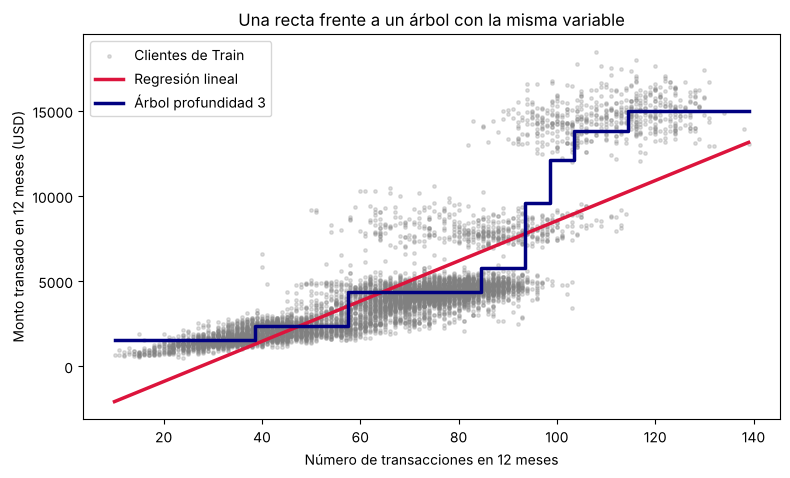

R² en Validation — recta: 0.642  árbol: 0.798


In [20]:
# Una sola variable para poder ver recta y escalones en el mismo gráfico.
x1_train = X_train_bc[['Total_Trans_Ct']]
x1_val = X_val_bc[['Total_Trans_Ct']]
recta_1v = LinearRegression().fit(x1_train, y_train_bc)
arbol_1v = DecisionTreeRegressor(max_depth=3, random_state=42).fit(x1_train, y_train_bc)

malla = pd.DataFrame({'Total_Trans_Ct': np.arange(10, 140)})
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(x1_train['Total_Trans_Ct'], y_train_bc, s=6, alpha=0.25, color='grey', label='Clientes de Train')
ax.plot(malla['Total_Trans_Ct'], recta_1v.predict(malla), color='crimson', lw=2.5, label='Regresión lineal')
ax.step(malla['Total_Trans_Ct'], arbol_1v.predict(malla), where='mid', color='navy', lw=2.5, label='Árbol profundidad 3')
ax.set_xlabel('Número de transacciones en 12 meses')
ax.set_ylabel('Monto transado en 12 meses (USD)')
ax.set_title('Una recta frente a un árbol con la misma variable')
ax.legend()
plt.show()

print('R² en Validation — recta:', round(r2_score(y_val_bc, recta_1v.predict(x1_val)), 3),
      ' árbol:', round(r2_score(y_val_bc, arbol_1v.predict(x1_val)), 3))

**Interpretación.** La nube no es una recta: hasta unas 90 transacciones el monto sube despacio y, a partir de ahí, salta a otro nivel. La recta (R² cercano a 0,64) pasa por el medio y se equivoca en ambos grupos; los escalones del árbol (R² cercano a 0,80) siguen esos saltos. Fíjate también en los extremos: el árbol no puede predecir más que el promedio de su última hoja, aunque llegue un cliente con más transacciones de las vistas.

## 7.3 ¿Cómo decide un árbol de regresión dónde cortar?

Prueba pares «variable ≤ umbral» en las filas de Train. En cada división candidata calcula el promedio de `y` a izquierda y derecha, y cuánto se alejan los valores reales de esos promedios. Una partición útil reduce la **suma de errores cuadrados** (SSE) respecto a mantener un único promedio en el nodo.

Ejemplo: si `y = [1, 2, 8, 9]`, un nodo único predice 5 para todos y tiene SSE = 50. Separar `[1,2]` y `[8,9]` permite predecir 1,5 y 8,5; el SSE cae a 1. El árbol prefiere umbrales que produzcan mayores reducciones de SSE. Eso no demuestra que la variable del corte cause el monto: solo fue útil para separar esta muestra.

La sección de clasificación usará otra impureza (Gini). No mezcles el SSE de regresión con el criterio de clases.

In [21]:
# Reproducimos la comparación de impureza de regresión con cuatro targets.
y_juguete = np.array([1., 2., 8., 9.])
pred_unica = np.repeat(y_juguete.mean(), len(y_juguete))
pred_dividida = np.r_[np.repeat(y_juguete[:2].mean(), 2),
                      np.repeat(y_juguete[2:].mean(), 2)]
sse_sin_corte = np.sum((y_juguete - pred_unica) ** 2)
sse_con_corte = np.sum((y_juguete - pred_dividida) ** 2)
print('Predicción nodo único:', pred_unica[0], 'SSE:', sse_sin_corte)
print('Predicción hojas:', pred_dividida, 'SSE:', sse_con_corte)


Predicción nodo único: 5.0 SSE: 50.0
Predicción hojas: [1.5 1.5 8.5 8.5] SSE: 1.0


**Interpretación:** el árbol no aprende una pendiente única. Decide que dos regiones de X tengan promedios distintos; la mejora en SSE de Train puede ser señal o ruido. Validation mostrará si esas particiones ayudan en filas que no participaron en el ajuste.

# 8. Un árbol de regresión con las cinco variables

`DecisionTreeRegressor` recibe `X_train_bc` e `y_train_bc`, exactamente como `LinearRegression`. `fit()` aprende umbrales con Train; `predict()` recorre el árbol para cada fila de Validation. Fijamos `max_depth=3` solo para construir un **primer** árbol legible. Comparamos con una regresión lineal que recibe las mismas cinco columnas y el mismo Train.

In [22]:
lineal_bc = LinearRegression().fit(X_train_bc, y_train_bc)
arbol_bc_3 = DecisionTreeRegressor(max_depth=3, random_state=42).fit(X_train_bc, y_train_bc)

tabla_linea_arbol_bc = pd.DataFrame([
    {'modelo': 'Regresión lineal', 'conjunto': 'Train', **metricas_regresion(y_train_bc, lineal_bc.predict(X_train_bc))},
    {'modelo': 'Regresión lineal', 'conjunto': 'Validation', **metricas_regresion(y_val_bc, lineal_bc.predict(X_val_bc))},
    {'modelo': 'Árbol profundidad 3', 'conjunto': 'Train', **metricas_regresion(y_train_bc, arbol_bc_3.predict(X_train_bc))},
    {'modelo': 'Árbol profundidad 3', 'conjunto': 'Validation', **metricas_regresion(y_val_bc, arbol_bc_3.predict(X_val_bc))},
])
tabla_linea_arbol_bc.set_index(['modelo', 'conjunto']).round(3)

MAE          MSE      RMSE     R2    Bias
modelo              conjunto                                                  
Regresión lineal    Train       1414.771  3672528.851  1916.384  0.692   0.000
                    Validation  1346.985  3451725.356  1857.882  0.678   5.698
Árbol profundidad 3 Train        830.893  1868143.068  1366.800  0.843  -0.000
                    Validation   839.521  1916232.826  1384.281  0.821 -23.654

**Lee la tabla.** Aquí el árbol sí mejora a la recta **también en Validation**: el MAE baja de unos 1 350 a unos 840 dólares y el R² sube de 0,68 a 0,82. Además, Train y Validation se parecen en ambos modelos: con 7 088 filas de Train, ocho hojas no alcanzan a memorizar.

## 8.1 Ver el árbol dibujado

`plot_tree` dibuja cada nodo como un recuadro. Arriba está la pregunta; `samples` es cuántas filas de Train llegaron a ese nodo; `value` es su promedio de monto (la predicción si el árbol se detuviera ahí). Un color más intenso indica un promedio más alto. Si la respuesta a la pregunta es **sí** (verdadero), se baja por la izquierda.

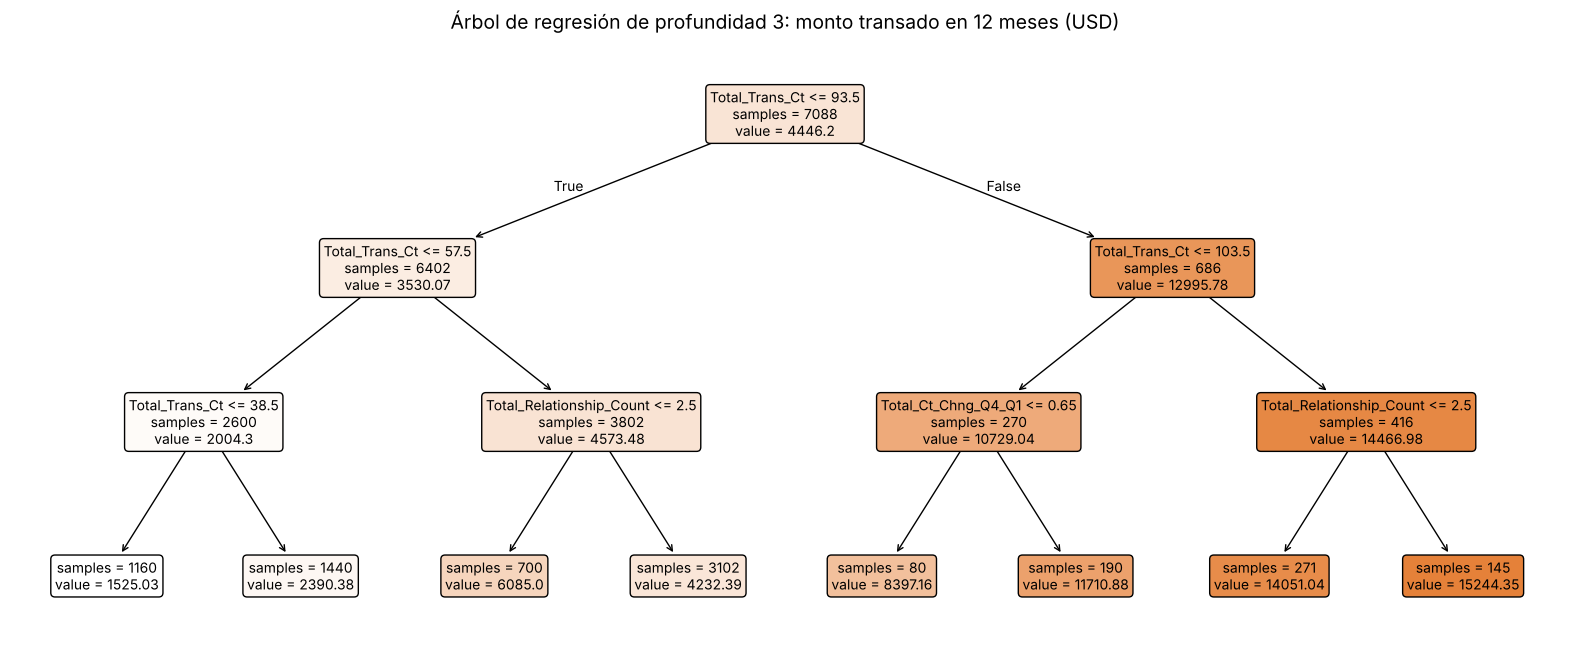

In [23]:
fig, ax = plt.subplots(figsize=(20, 8))
plot_tree(arbol_bc_3, feature_names=FEATURES_BC, filled=True, rounded=True,
          impurity=False, precision=2, fontsize=10, ax=ax)
ax.set_title('Árbol de regresión de profundidad 3: monto transado en 12 meses (USD)', fontsize=14)
plt.show()

In [24]:
# La misma información en texto: útil para copiar las reglas.
from sklearn.tree import export_text
print(export_text(arbol_bc_3, feature_names=FEATURES_BC, decimals=2))

|--- Total_Trans_Ct <= 93.50
|   |--- Total_Trans_Ct <= 57.50
|   |   |--- Total_Trans_Ct <= 38.50
|   |   |   |--- value: [1525.03]
|   |   |--- Total_Trans_Ct >  38.50
|   |   |   |--- value: [2390.38]
|   |--- Total_Trans_Ct >  57.50
|   |   |--- Total_Relationship_Count <= 2.50
|   |   |   |--- value: [6085.00]
|   |   |--- Total_Relationship_Count >  2.50
|   |   |   |--- value: [4232.39]
|--- Total_Trans_Ct >  93.50
|   |--- Total_Trans_Ct <= 103.50
|   |   |--- Total_Ct_Chng_Q4_Q1 <= 0.65
|   |   |   |--- value: [8397.16]
|   |   |--- Total_Ct_Chng_Q4_Q1 >  0.65
|   |   |   |--- value: [11710.88]
|   |--- Total_Trans_Ct >  103.50
|   |   |--- Total_Relationship_Count <= 2.50
|   |   |   |--- value: [14051.04]
|   |   |--- Total_Relationship_Count >  2.50
|   |   |   |--- value: [15244.35]



**Lee el dibujo.** La primera pregunta es sobre el número de transacciones (≤ 93,5): es la división que más redujo el SSE en Train. En el segundo nivel las dos preguntas vuelven a ser sobre transacciones (≤ 57,5 y ≤ 103,5); en el tercero aparecen el número de productos con el banco y el cambio de actividad entre trimestres. La hoja con más filas (3 102 clientes) predice unos 4 232 dólares. La edad y el límite de crédito no aparecen: en estos tres niveles no fueron las mejores preguntas.

Que «tener 2 productos o menos» lleve a un monto mayor **no** significa que vender menos productos haga gastar más: el árbol solo encontró que esa pregunta separa bien a estos clientes.

In [25]:
# Un cliente de Validation para seguir la ruta a mano (no es Test).
cliente = X_val_bc.iloc[[0]]
caso_bc = cliente.copy()
caso_bc['monto_real'] = y_val_bc.iloc[0]
caso_bc['pred_lineal'] = lineal_bc.predict(cliente)
caso_bc['pred_arbol'] = arbol_bc_3.predict(cliente)
caso_bc.round(2)

,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Total_Relationship_Count,Customer_Age,Credit_Limit,monto_real,pred_lineal,pred_arbol
551,34,0.31,4,40,23981.0,1421,1465.68,1525.03


**Sigue la ruta.** Este cliente hizo 34 transacciones: ¿34 ≤ 93,5? sí; ¿34 ≤ 57,5? sí; ¿34 ≤ 38,5? sí. Llega a la hoja de 1 160 clientes con promedio cercano a 1 525 dólares. Compara esa predicción con el monto real y con la recta. La ruta explica **por qué** el árbol dio ese número; no prueba un mecanismo causal.

# 9. Los tres hiperparámetros del árbol

Un **parámetro** lo aprende el modelo con Train: en el árbol, las preguntas, los umbrales y los promedios de las hojas. Un **hiperparámetro** lo decide el analista **antes** de `fit()`. El árbol de scikit-learn tiene tres que controlan cuánto puede crecer:

| Hiperparámetro | Qué limita | Cuándo actúa | Valor por defecto |
|---|---|---|---|
| `max_depth` | Cuántas preguntas encadenadas hay de la raíz a una hoja | En todo el árbol | `None`: sin límite |
| `min_samples_split` | Cuántas filas debe tener un nodo **para intentar dividirlo** | **Antes** de cortar | 2 |
| `min_samples_leaf` | Cuántas filas debe tener **cada hoja que resulta** de un corte | **Después** de cortar | 1 |

**La diferencia entre los dos últimos.** Con `min_samples_split=100`, un nodo de 100 clientes sí puede dividirse, incluso en 99 y 1. Con `min_samples_leaf=50`, ese corte queda prohibido porque una de las hojas tendría menos de 50. El primero decide **si se pregunta**; el segundo decide **qué cortes son aceptables**.

Con los valores por defecto (sin límite de profundidad, 2 y 1), el árbol sigue preguntando hasta que cada hoja tenga clientes con el mismo monto: suele terminar memorizando Train. Los elegiremos comparando en Validation, nunca mirando Test.

## 9.1 Ver cómo el algoritmo divide los datos

Con dos variables podemos dibujar lo que hace el árbol: cada pregunta traza una línea vertical u horizontal y cada hoja es un **rectángulo** pintado con su promedio. Usaremos el número de transacciones y su cambio entre trimestres. Mira cómo cada nivel adicional subdivide los rectángulos del nivel anterior.

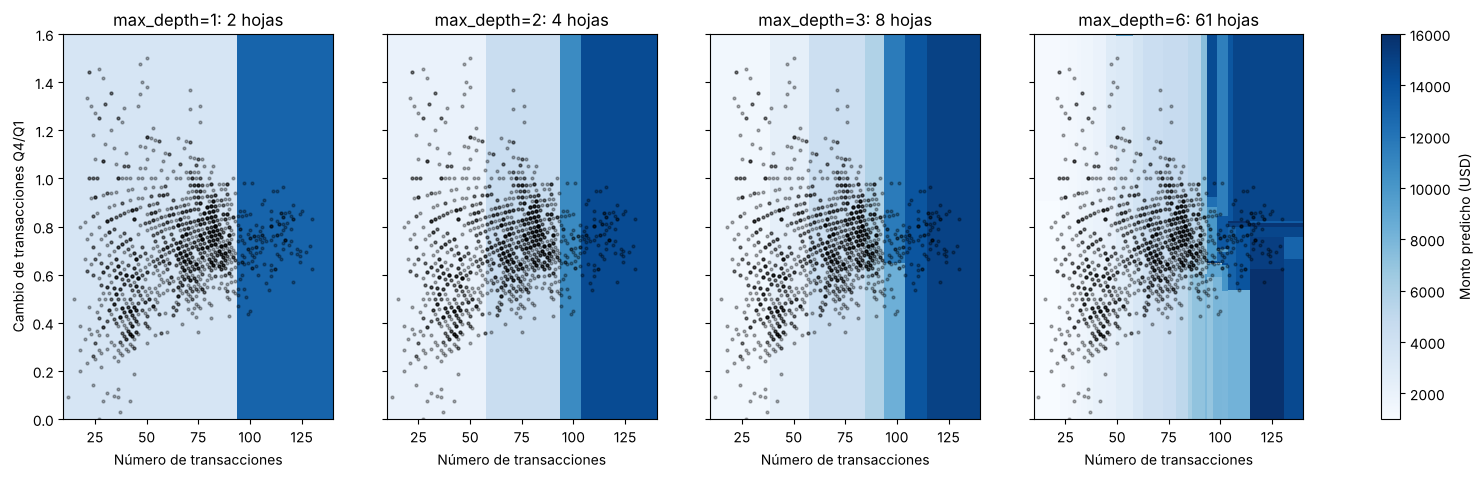

In [26]:
dos_vars = ['Total_Trans_Ct', 'Total_Ct_Chng_Q4_Q1']
gx, gy = np.meshgrid(np.linspace(10, 140, 300), np.linspace(0, 1.6, 300))
malla_2v = pd.DataFrame({'Total_Trans_Ct': gx.ravel(), 'Total_Ct_Chng_Q4_Q1': gy.ravel()})
muestra = X_train_bc.sample(1500, random_state=42)

fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharey=True)
for ax, profundidad in zip(axes, [1, 2, 3, 6]):
    arbol_2v = DecisionTreeRegressor(max_depth=profundidad, random_state=42).fit(X_train_bc[dos_vars], y_train_bc)
    zona = arbol_2v.predict(malla_2v).reshape(gx.shape)
    pintura = ax.pcolormesh(gx, gy, zona, cmap='Blues', vmin=1000, vmax=16000, shading='auto')
    ax.scatter(muestra['Total_Trans_Ct'], muestra['Total_Ct_Chng_Q4_Q1'], s=4, color='black', alpha=0.3)
    ax.set_title(f'max_depth={profundidad}: {arbol_2v.get_n_leaves()} hojas')
    ax.set_xlabel('Número de transacciones'); ax.set_ylim(0, 1.6)
axes[0].set_ylabel('Cambio de transacciones Q4/Q1')
fig.colorbar(pintura, ax=axes, label='Monto predicho (USD)')
plt.show()

**Interpretación.** Con profundidad 1 hay una sola línea vertical: el árbol solo separa «muchas» y «pocas» transacciones. Con 2 y 3 aparecen más líneas y rectángulos más pequeños. Con 6 hay decenas de rectángulos, algunos muy estrechos alrededor de pocos puntos: esa es la imagen del sobreajuste. En los tres primeros niveles todas las líneas son verticales: el árbol prefiere preguntar por el número de transacciones, y las líneas horizontales (cambio entre trimestres) recién aparecen con más profundidad. Las fronteras son siempre paralelas a los ejes porque cada pregunta usa una sola variable.

## 9.2 Jugar con `max_depth`

Ahora usamos las cinco variables y probamos profundidades de 1 a 20. Para cada una registramos el R² de Train y de Validation. Si Train sigue subiendo mientras Validation baja, el árbol está aprendiendo detalles que no se repiten en clientes nuevos.

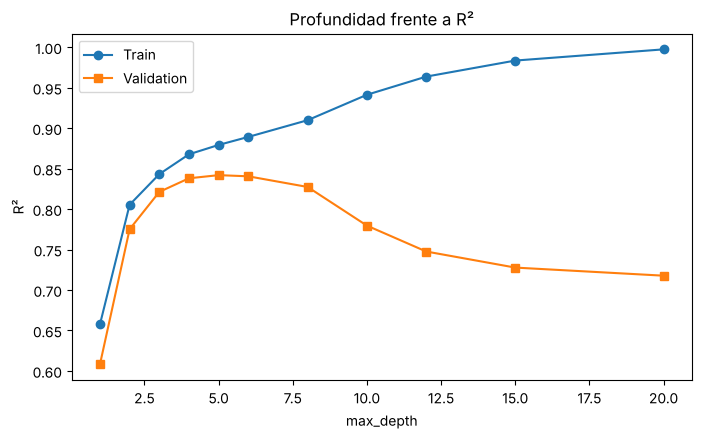

,max_depth,hojas,R2_train,R2_validation,MAE_validation
0,1,2,0.658,0.608,1554.046
1,2,4,0.805,0.775,952.929
2,3,8,0.843,0.821,839.521
3,4,16,0.868,0.838,772.052
4,5,32,0.879,0.842,761.827
5,6,62,0.889,0.840,752.782
6,8,215,0.910,0.827,767.239
7,10,609,0.941,0.780,815.980
8,12,1283,0.964,0.748,860.198
9,15,2864,0.984,0.728,900.688


In [27]:
filas_prof = []
for profundidad in [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20]:
    m = DecisionTreeRegressor(max_depth=profundidad, random_state=42).fit(X_train_bc, y_train_bc)
    filas_prof.append({'max_depth': profundidad, 'hojas': m.get_n_leaves(),
                       'R2_train': r2_score(y_train_bc, m.predict(X_train_bc)),
                       'R2_validation': r2_score(y_val_bc, m.predict(X_val_bc)),
                       'MAE_validation': mean_absolute_error(y_val_bc, m.predict(X_val_bc))})
tabla_prof = pd.DataFrame(filas_prof)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(tabla_prof['max_depth'], tabla_prof['R2_train'], marker='o', label='Train')
ax.plot(tabla_prof['max_depth'], tabla_prof['R2_validation'], marker='s', label='Validation')
ax.set_xlabel('max_depth'); ax.set_ylabel('R²'); ax.set_title('Profundidad frente a R²'); ax.legend()
plt.show()
tabla_prof.round(3)

**Interpretación.** Validation mejora hasta profundidad 5 (R² cercano a 0,84) y luego empeora; con profundidad 20 baja a cerca de 0,72 aunque Train llegue casi a 1. El número de hojas crece muy rápido: limitar la profundidad es la manera más directa de evitar que el árbol memorice.

## 9.3 Jugar con `min_samples_leaf`

Ahora dejamos la profundidad sin límite y exigimos un mínimo de clientes en cada hoja. Con 1 (el valor por defecto) una hoja puede describir a un solo cliente. Al subir el mínimo, el árbol deja de crear hojas pequeñas, aunque la profundidad no esté limitada.

In [28]:
filas_hoja = []
for minimo in [1, 5, 20, 50, 200, 1000]:
    m = DecisionTreeRegressor(min_samples_leaf=minimo, random_state=42).fit(X_train_bc, y_train_bc)
    filas_hoja.append({'min_samples_leaf': minimo, 'profundidad_real': m.get_depth(), 'hojas': m.get_n_leaves(),
                       'R2_train': r2_score(y_train_bc, m.predict(X_train_bc)),
                       'R2_validation': r2_score(y_val_bc, m.predict(X_val_bc)),
                       'MAE_validation': mean_absolute_error(y_val_bc, m.predict(X_val_bc))})
tabla_hoja = pd.DataFrame(filas_hoja)
tabla_hoja.round(3)

,min_samples_leaf,profundidad_real,hojas,R2_train,R2_validation,MAE_validation
0,1,32,7080,1.000,0.724,962.005
1,5,26,1135,0.936,0.809,826.370
2,20,18,272,0.894,0.848,747.063
3,50,12,106,0.878,0.847,744.567
4,200,8,26,0.855,0.829,794.350
5,1000,3,5,0.670,0.660,1142.145


**Interpretación.** Con `min_samples_leaf=1` el árbol crea unas 7 000 hojas para 7 088 clientes: casi una por cliente, R² de Train 1,00 y de Validation cercano a 0,72. Con 20 clientes por hoja quedan unas 270 hojas y Validation sube a cerca de 0,85, el mejor de la tabla. Con 1 000 por hoja solo caben 5 hojas: el árbol queda demasiado simple y Validation cae a cerca de 0,66. Hay un punto intermedio: ni hojas de un cliente, ni hojas gigantes.

## 9.4 Jugar con `min_samples_split`

Volvemos a dejar todo sin límite y ahora exigimos un mínimo de clientes **en un nodo para que se pueda seguir preguntando**. Observa que el efecto se parece al de `min_samples_leaf`, pero los números de hojas no coinciden: uno actúa antes del corte y el otro después.

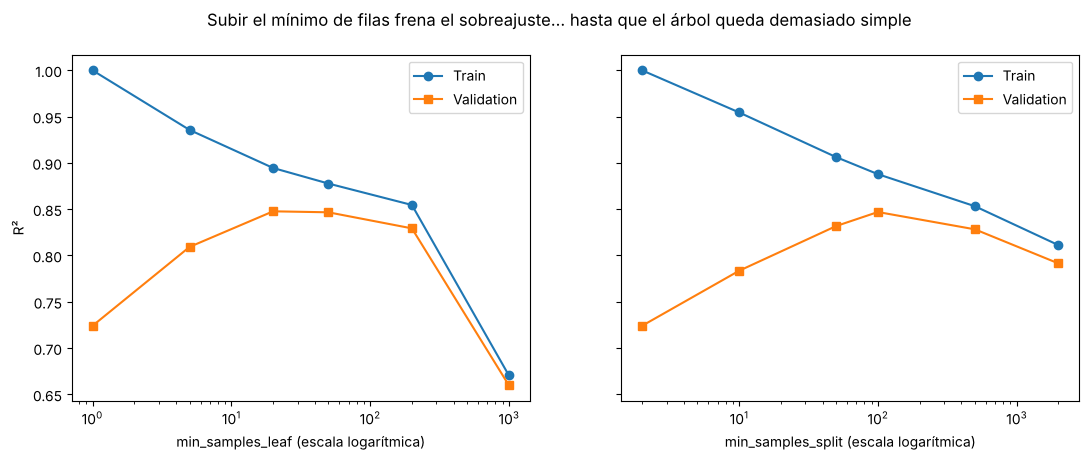

,min_samples_split,profundidad_real,hojas,R2_train,R2_validation,MAE_validation
0,2,32,7080,1.000,0.724,962.005
1,10,27,1523,0.954,0.784,885.761
2,50,22,357,0.906,0.832,779.428
3,100,17,166,0.888,0.847,757.507
4,500,12,24,0.853,0.828,793.703
5,2000,4,6,0.811,0.791,886.878


In [29]:
filas_split = []
for minimo in [2, 10, 50, 100, 500, 2000]:
    m = DecisionTreeRegressor(min_samples_split=minimo, random_state=42).fit(X_train_bc, y_train_bc)
    filas_split.append({'min_samples_split': minimo, 'profundidad_real': m.get_depth(), 'hojas': m.get_n_leaves(),
                        'R2_train': r2_score(y_train_bc, m.predict(X_train_bc)),
                        'R2_validation': r2_score(y_val_bc, m.predict(X_val_bc)),
                        'MAE_validation': mean_absolute_error(y_val_bc, m.predict(X_val_bc))})
tabla_split = pd.DataFrame(filas_split)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, tabla_h, col in [(axes[0], tabla_hoja, 'min_samples_leaf'), (axes[1], tabla_split, 'min_samples_split')]:
    ax.plot(tabla_h[col], tabla_h['R2_train'], marker='o', label='Train')
    ax.plot(tabla_h[col], tabla_h['R2_validation'], marker='s', label='Validation')
    ax.set_xscale('log'); ax.set_xlabel(col + ' (escala logarítmica)'); ax.legend()
axes[0].set_ylabel('R²')
fig.suptitle('Subir el mínimo de filas frena el sobreajuste… hasta que el árbol queda demasiado simple')
plt.show()
tabla_split.round(3)

**Interpretación.** Con `min_samples_split=2` (el valor por defecto) obtenemos el mismo árbol que memoriza. Con 100 quedan unas 170 hojas y Validation llega a cerca de 0,85; con 2 000 solo quedan 6 hojas y vuelve a caer. En las dos curvas la brecha entre Train y Validation se cierra al subir el mínimo: el árbol ya no puede crear reglas para casos aislados.

## 9.5 El mismo árbol con distintos hiperparámetros

Dibujemos tres árboles con `max_depth=3` para ver **cómo cambia la forma** al agregar los otros dos límites:

- **A:** solo `max_depth=3`.
- **B:** además `min_samples_leaf=600`: ninguna hoja puede tener menos de 600 clientes.
- **C:** además `min_samples_split=4000`: solo se divide un nodo que tenga al menos 4 000 clientes.

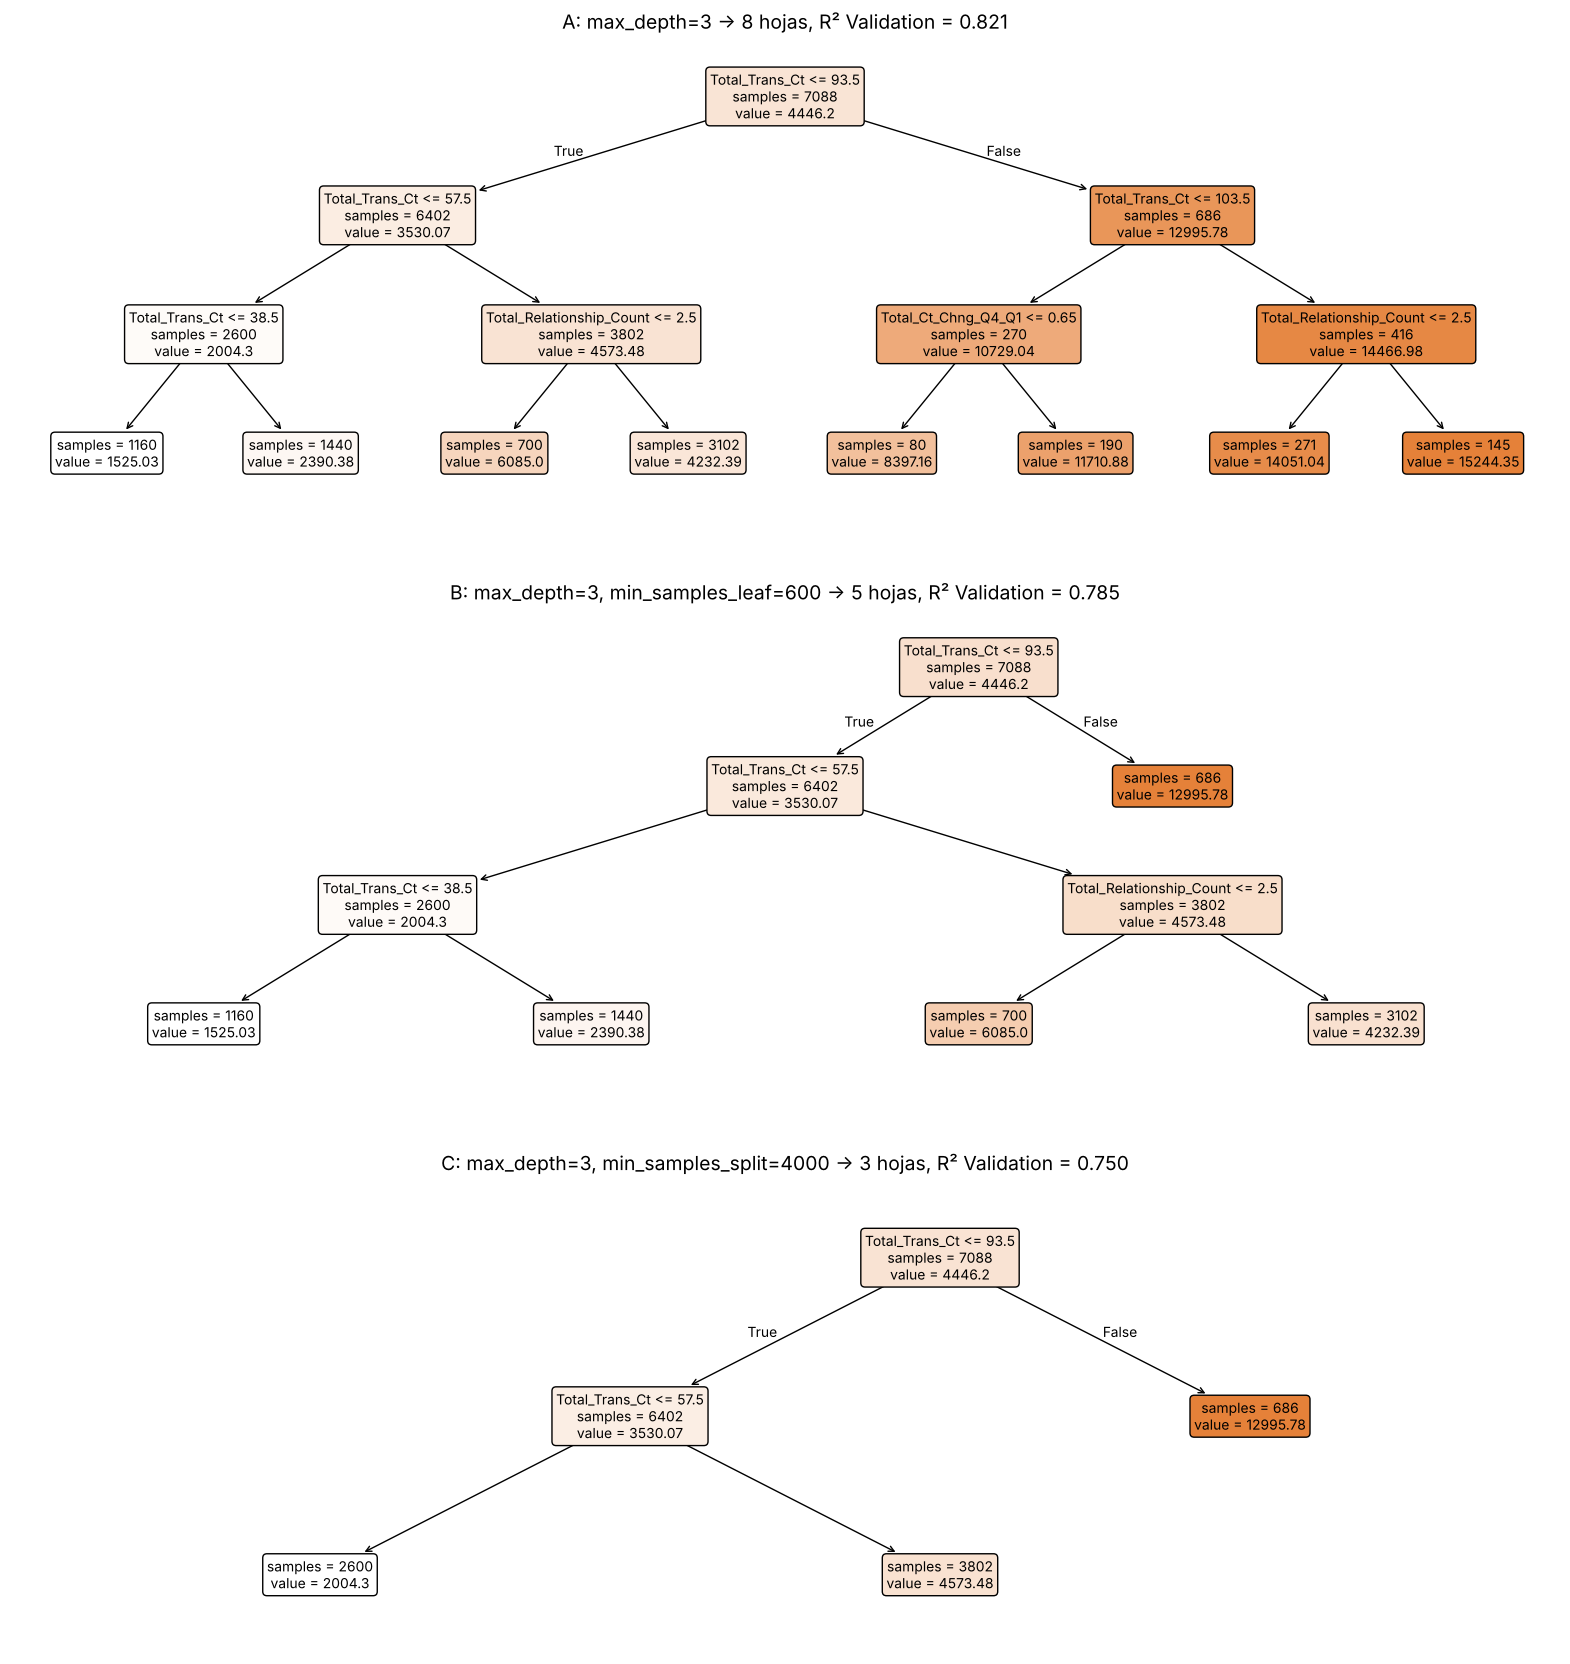

In [30]:
configs_dibujo = [('A: max_depth=3', dict(max_depth=3)),
                  ('B: max_depth=3, min_samples_leaf=600', dict(max_depth=3, min_samples_leaf=600)),
                  ('C: max_depth=3, min_samples_split=4000', dict(max_depth=3, min_samples_split=4000))]
fig, axes = plt.subplots(3, 1, figsize=(20, 21))
for ax, (titulo, params) in zip(axes, configs_dibujo):
    m = DecisionTreeRegressor(random_state=42, **params).fit(X_train_bc, y_train_bc)
    plot_tree(m, feature_names=FEATURES_BC, filled=True, rounded=True, impurity=False,
              precision=2, fontsize=10, ax=ax)
    ax.set_title(f'{titulo} → {m.get_n_leaves()} hojas, R² Validation = '
                 f'{r2_score(y_val_bc, m.predict(X_val_bc)):.3f}', fontsize=14)
plt.show()

**Interpretación.** El árbol A tiene 8 hojas, entre ellas una de solo 80 clientes. En B desaparecen los cortes que dejaban hojas pequeñas: quedan 5 hojas, todas con al menos 600 clientes. En C, los nodos con menos de 4 000 clientes ya no se dividen, así que el árbol se detiene antes, en profundidad 2. B y C pierden algo de R² en Validation frente a A: en este caso esos límites son **demasiado** estrictos, y eso también se aprende comparando.

## 9.6 Laboratorio: prueba tus propios valores

Cambia los tres números de la celda siguiente y vuelve a ejecutarla. Anota en una tabla cuántas hojas obtienes y el R² de Train y de Validation. El dibujo muestra solo los tres primeros niveles para que se pueda leer.

Profundidad real: 4 | Hojas: 16
R² Train: 0.868 | R² Validation: 0.838 | MAE Validation: 772.1


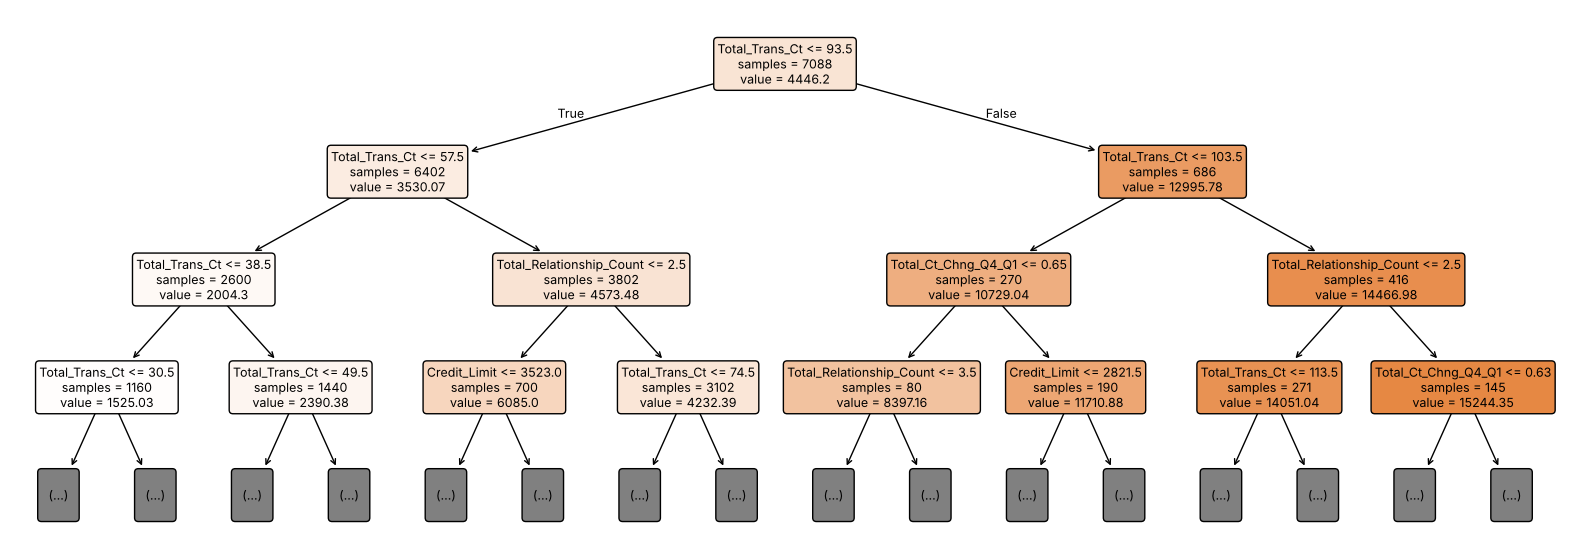

In [31]:
PROFUNDIDAD = 4       # prueba None, 2, 6, 10...
MIN_SPLIT = 2         # prueba 10, 100, 1000...
MIN_LEAF = 1          # prueba 5, 20, 200...

mi_arbol = DecisionTreeRegressor(max_depth=PROFUNDIDAD, min_samples_split=MIN_SPLIT,
                                 min_samples_leaf=MIN_LEAF, random_state=42).fit(X_train_bc, y_train_bc)
print('Profundidad real:', mi_arbol.get_depth(), '| Hojas:', mi_arbol.get_n_leaves())
print('R² Train:', round(r2_score(y_train_bc, mi_arbol.predict(X_train_bc)), 3),
      '| R² Validation:', round(r2_score(y_val_bc, mi_arbol.predict(X_val_bc)), 3),
      '| MAE Validation:', round(mean_absolute_error(y_val_bc, mi_arbol.predict(X_val_bc)), 1))
fig, ax = plt.subplots(figsize=(20, 7))
plot_tree(mi_arbol, feature_names=FEATURES_BC, filled=True, rounded=True, impurity=False,
          precision=2, fontsize=9, max_depth=3, ax=ax)
plt.show()

# 10. Demostración: underfitting y overfitting del árbol de regresión

Resumimos con tres árboles: uno muy corto (`max_depth=1`), uno intermedio (`max_depth=4`) y uno sin ningún límite. Todos usan **el mismo** Train y Validation. Revisaremos MAE, MSE, RMSE, R² y Bias; Bias solo no puede descartar errores grandes que se cancelen.

In [32]:
configuraciones_arbol = [
    {'modelo': 'Muy simple', 'max_depth': 1},
    {'modelo': 'Intermedio', 'max_depth': 4},
    {'modelo': 'Sin límite', 'max_depth': None},
]
resultados_arbol_reg = []
modelos_arbol_reg = {}
for config in configuraciones_arbol:
    modelo = DecisionTreeRegressor(max_depth=config['max_depth'], random_state=42)
    modelo.fit(X_train_bc, y_train_bc)
    modelos_arbol_reg[config['modelo']] = modelo
    met_train = metricas_regresion(y_train_bc, modelo.predict(X_train_bc))
    met_val = metricas_regresion(y_val_bc, modelo.predict(X_val_bc))
    fila = {'modelo': config['modelo'], 'max_depth': str(config['max_depth']), 'hojas': modelo.get_n_leaves()}
    fila.update({f'{k}_train': v for k, v in met_train.items()})
    fila.update({f'{k}_validation': v for k, v in met_val.items()})
    resultados_arbol_reg.append(fila)

tabla_overfitting = pd.DataFrame(resultados_arbol_reg)
tabla_overfitting['brecha_R2'] = tabla_overfitting['R2_train'] - tabla_overfitting['R2_validation']
tabla_overfitting[['modelo', 'max_depth', 'hojas', 'MAE_train', 'MAE_validation',
                   'R2_train', 'R2_validation', 'brecha_R2']].round(3)

,modelo,max_depth,hojas,MAE_train,MAE_validation,R2_train,R2_validation,brecha_R2
0,Muy simple,1,2,1514.790,1554.046,0.658,0.608,0.049
1,Intermedio,4,16,739.235,772.052,0.868,0.838,0.030
2,Sin límite,None,7080,0.709,962.005,1.000,0.724,0.276


### Diagnosticar el ajuste con las mismas filas

El árbol muy simple tiene errores altos en ambos conjuntos: **subajuste**. El intermedio mejora en los dos y su brecha es pequeña. El árbol sin límite tiene MAE de Train igual a 0 y R² de Train igual a 1, pero en Validation es peor que el intermedio: **sobreajuste**. Un R² de Train cercano a 1 no compensa una caída en Validation. No existe un umbral universal para declarar overfitting: compara también con la regresión lineal.

# 11. K-Fold y estabilidad del árbol de regresión

Una sola Validation puede favorecer por azar a cierto umbral. Usamos el conjunto de desarrollo de BankChurners (Train + Validation, sin Test) y el mismo objeto `kfold` de la sección 6 (5 folds, `shuffle=True`, `random_state=42`) para comparar la recta con un árbol de profundidad 4 y al menos 20 clientes por hoja. Dentro de cada fold cada modelo se ajusta desde cero.

> **Nota para quien viene de estadística:** `scoring={'MAE': 'neg_mean_absolute_error', ...}` y la línea `-cv_arbol['test_MAE']` más abajo no son un error de signo. Scikit-learn exige que "mayor puntaje sea siempre mejor"; como un MAE más bajo es mejor, la librería lo niega internamente, y por eso hay que volver a negarlo para recuperar el MAE real. El notebook complementario [Día 0.1, Sección 5.3](00_1_Dia0_Puente_a_Scikit_Learn.ipynb) explica esta convención con más detalle.

In [33]:
X_dev_bc = pd.concat([X_train_bc, X_val_bc])
y_dev_bc = pd.concat([y_train_bc, y_val_bc])
puntajes = {'MAE': 'neg_mean_absolute_error', 'R2': 'r2'}

cv_lineal_bc = cross_validate(LinearRegression(), X_dev_bc, y_dev_bc, cv=kfold, scoring=puntajes)
cv_arbol = cross_validate(DecisionTreeRegressor(max_depth=4, min_samples_leaf=20, random_state=42),
                          X_dev_bc, y_dev_bc, cv=kfold, scoring=puntajes)

tabla_cv_bc = pd.DataFrame({'fold': np.arange(1, 6),
                            'MAE_lineal': -cv_lineal_bc['test_MAE'], 'MAE_arbol': -cv_arbol['test_MAE'],
                            'R2_lineal': cv_lineal_bc['test_R2'], 'R2_arbol': cv_arbol['test_R2']})
print(tabla_cv_bc.round(3))
pd.DataFrame({'modelo': ['Regresión lineal', 'Árbol (prof. 4, hoja ≥ 20)'],
              'MAE_promedio': [tabla_cv_bc['MAE_lineal'].mean(), tabla_cv_bc['MAE_arbol'].mean()],
              'MAE_std': [tabla_cv_bc['MAE_lineal'].std(), tabla_cv_bc['MAE_arbol'].std()],
              'R2_promedio': [tabla_cv_bc['R2_lineal'].mean(), tabla_cv_bc['R2_arbol'].mean()]}).round(3)

   fold  MAE_lineal  MAE_arbol  R2_lineal  R2_arbol
0     1    1399.494    779.491      0.691     0.852
1     2    1380.507    726.507      0.672     0.856
2     3    1404.636    771.330      0.696     0.856
3     4    1376.478    745.772      0.696     0.855
4     5    1440.941    775.809      0.686     0.860


,modelo,MAE_promedio,MAE_std,R2_promedio
0,Regresión lineal,1400.411,25.644,0.688
1,"Árbol (prof. 4, hoja ≥ 20)",759.782,22.816,0.856


### ¿Qué añade K-Fold a la comparación línea/árbol?

El árbol gana en **los cinco** folds, no solo en una Validation afortunada. El promedio de MAE indica el error típico; la desviación muestra cuánto varía al cambiar qué clientes validan. Con miles de filas los cinco resultados se parecen mucho: compáralo con el panel del Banco Mundial, donde cada fold tenía unas 21 filas y el error cambiaba bastante de una vuelta a otra.

# 12. Random Forest para regresión: promediar varios árboles

Un solo árbol cambia mucho si varía Train. `RandomForestRegressor` entrena muchos árboles sobre muestras bootstrap (filas sorteadas con reemplazo); en cada división también considera un subconjunto aleatorio de variables, y promedia las predicciones. Esto suele reducir la inestabilidad de un árbol flexible, pero no garantiza superar a otros modelos: hay que comparar.

Usamos 100 árboles con `max_depth=8` y `min_samples_leaf=5`: cada árbol puede ser bastante detallado porque el promedio compensa parte de su variabilidad.

In [34]:
bosque_reg = RandomForestRegressor(n_estimators=100, max_depth=8, min_samples_leaf=5,
                                   random_state=42, n_jobs=1)
bosque_reg.fit(X_train_bc, y_train_bc)
pd.DataFrame({
    'Train': metricas_regresion(y_train_bc, bosque_reg.predict(X_train_bc)),
    'Validation': metricas_regresion(y_val_bc, bosque_reg.predict(X_val_bc)),
}).T.round(3)

,MAE,MSE,RMSE,R2,Bias
Train,611.903,1052710.739,1026.017,0.912,-2.217
Validation,710.293,1472044.746,1213.279,0.863,-33.383


### Compara recta, árbol y bosque en la misma Validation

Los tres modelos aprendieron del mismo Train y responden sobre los mismos clientes de Validation.

In [35]:
modelos_regresion = {
    'Regresión lineal': lineal_bc,
    'Árbol intermedio (prof. 4)': modelos_arbol_reg['Intermedio'],
    'Random Forest': bosque_reg,
}
filas_comparacion_reg = [{'modelo': nombre, **metricas_regresion(y_val_bc, est.predict(X_val_bc))}
                         for nombre, est in modelos_regresion.items()]
pd.DataFrame(filas_comparacion_reg).set_index('modelo').sort_values('MAE').round(3)

,MAE,MSE,RMSE,R2,Bias
modelo,,,,,
Random Forest,710.293,1472044.746,1213.279,0.863,-33.383
Árbol intermedio (prof. 4),772.052,1735808.001,1317.501,0.838,-16.768
Regresión lineal,1346.985,3451725.356,1857.882,0.678,5.698


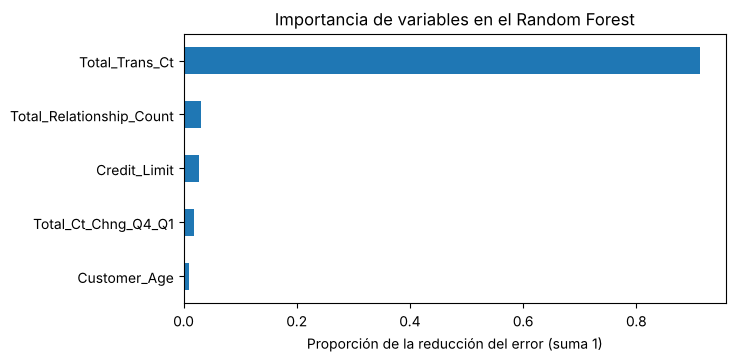

Total_Trans_Ct              0.913
Total_Relationship_Count    0.031
Credit_Limit                0.028
Total_Ct_Chng_Q4_Q1         0.019
Customer_Age                0.009
dtype: float64

In [36]:
# ¿Qué variables usó más el bosque para reducir el error?
importancias = pd.Series(bosque_reg.feature_importances_, index=FEATURES_BC).sort_values()
importancias.plot(kind='barh', figsize=(7, 3.5), title='Importancia de variables en el Random Forest')
plt.xlabel('Proporción de la reducción del error (suma 1)')
plt.show()
importancias.sort_values(ascending=False).round(3)

**Lectura guiada.** El bosque obtiene el menor MAE y el mayor R² en Validation: promediar 100 árboles mejoró al árbol solo y a la recta. Su brecha Train–Validation es pequeña, a pesar de usar árboles más profundos que el intermedio. La importancia indica que el número de transacciones concentra casi toda la reducción del error; eso es importancia **predictiva**, no un efecto causal, y no dice si la relación es positiva o negativa.

Compara con lo que ocurrió en el panel del Banco Mundial: allí el bosque no superó a la recta. La flexibilidad de árboles y bosques rinde cuando hay suficientes observaciones y una relación que no es una línea recta.